# Italy in numbers: who lives in hazard areas

ISPRA computes, for every one of Italy's 7,899 municipalities, how many
residents, families, buildings and businesses sit in landslide and flood
hazard areas. `municipalities()` downloads them all (about a minute the
first time, then from disk) and this notebook ranks them.

In [1]:
# pip install "ispra-idrogeo[geo]" matplotlib
from ispra_idrogeo import IdroGEO

idrogeo = IdroGEO()  # one client for the whole notebook; no account, no key

In [2]:
from datetime import timedelta

import pandas as pd

rows = await idrogeo.municipalities("pir", max_age=timedelta(days=30))
towns = pd.DataFrame(rows)
towns["landslide_p3p4"] = towns["pop_fr_p3"] + towns["pop_fr_p4"]
len(towns)

7899

## Most residents in high or very high landslide hazard (P3 + P4)

In [3]:
top = towns.nlargest(10, "landslide_p3p4")[["nome", "pop_res021", "landslide_p3p4", "popfrp3p4p"]]
top.columns = ["municipality", "residents", "in P3+P4", "% of residents"]
top.round(1)

,municipality,residents,in P3+P4,% of residents
5250,Napoli,921142,42390,4.6
1766,Genova,561203,30148,5.4
1653,Sanremo,52918,14607,27.6
5718,Chieti,48666,7188,14.8
5262,Pozzuoli,76952,6025,7.8
6595,Palermo,635439,5974,0.9
7640,Domodossola,17684,5943,33.6
4398,Massa,66498,5883,8.8
4410,Camaiore,31821,5750,18.1
1211,Cava de' Tirreni,51067,5371,10.5


## Most residents in medium flood hazard (P2: a flood every 100–200 years)

In [4]:
flood = towns.nlargest(10, "pop_idr_p2")[["nome", "pop_res021", "pop_idr_p2", "popidp2_p"]]
flood.columns = ["municipality", "residents", "in P2", "% of residents"]
flood.round(1)

,municipality,residents,in P2,% of residents
4471,Firenze,361619,182966,51.1
4021,Reggio nell'Emilia,169908,162082,100.0
4087,Bologna,387842,159903,43.1
4169,Ravenna,155836,153724,100.0
4141,Ferrara,129872,132545,100.0
4182,Forlì,116558,104373,89.6
4923,Roma,2749031,96576,3.7
7562,Rimini,149169,96411,69.1
3929,Piacenza,102364,90518,90.2
1766,Genova,561203,78207,13.3


## Region by region

In [5]:
regions = await idrogeo.summary("pir", "regioni")
figures = []
for region in regions:
    figures.append(await idrogeo.summary("pir", "regioni", region["cod_reg"]))
by_region = pd.DataFrame(figures)
by_region["landslide_p3p4"] = by_region["pop_fr_p3"] + by_region["pop_fr_p4"]
by_region = by_region.sort_values("landslide_p3p4")

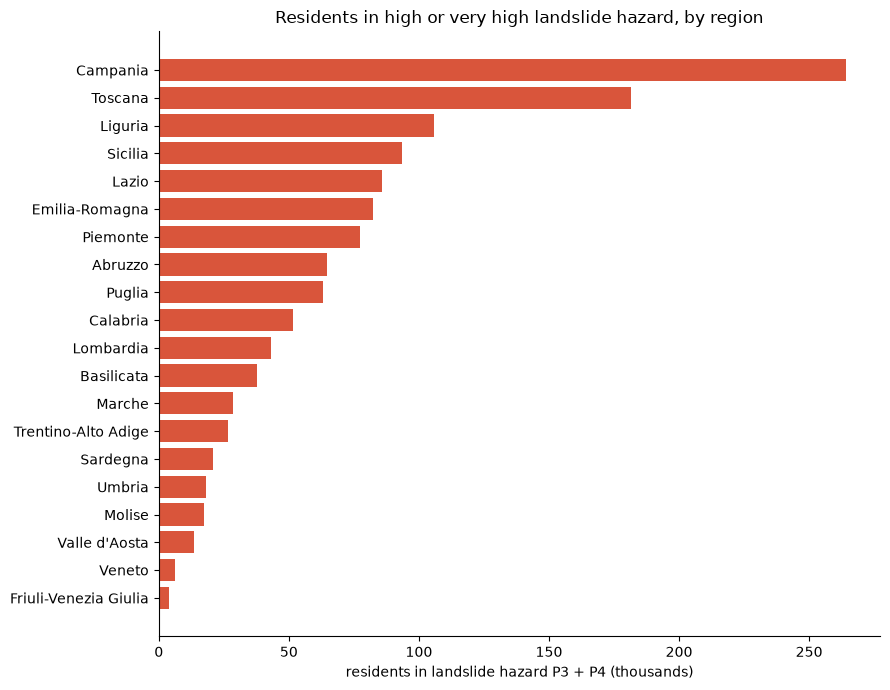

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(by_region["nome"], by_region["landslide_p3p4"] / 1000, color="#d9553b")
ax.set_xlabel("residents in landslide hazard P3 + P4 (thousands)")
ax.set_title("Residents in high or very high landslide hazard, by region")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [7]:
total = towns["landslide_p3p4"].sum()
print(f"Italy: {total:,} residents in P3+P4")  # the same as pir/italia

Italy: 1,284,960 residents in P3+P4


In [8]:
await idrogeo.aclose()

Source: ISPRA — IdroGEO (CC BY 4.0).